# 03. Sentiment & Review Text Analytics
**Deskripsi:** Analisis sentiment ulasan pembeli dan hubungannya terhadap rating serta jumlah barang terjual.


In [1]:
# 1. Load Processed Data dari 'data/processed/tokopedia_cleaned.csv'
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/tokopedia_cleaned.csv")

C:\Users\user\AppData\Local\Temp\ipykernel_1932\3635124989.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='sentiment_category', order=['Positive', 'Neutral', 'Negative'], palette=['#2ecc71', '#f1c40f', '#e74c3c'])


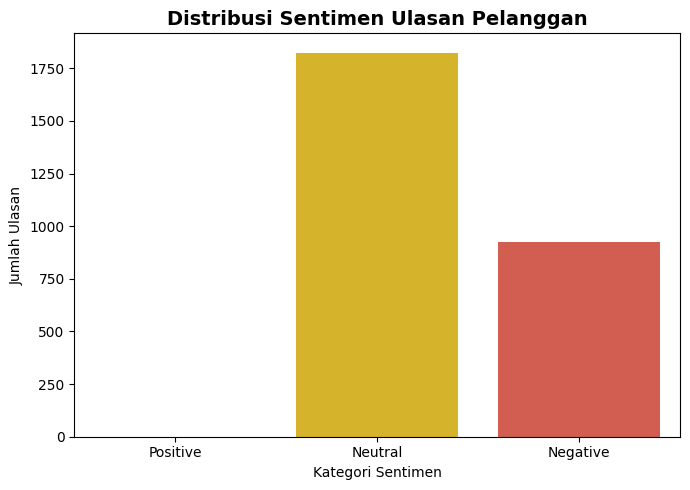

In [7]:
# 2. Distribusi Rating (1-5) dan Categorization Sentiment (Positive, Neutral, Negative)
# Fix typo in the source column name and keep later code compatible
if 'sentiment_category' not in df.columns and 'sentinent_category' in df.columns:
    df = df.rename(columns={'sentinent_category': 'sentiment_category'})

sentiment_counts = df['sentiment_category'].value_counts().reindex(
    ['Positive', 'Neutral', 'Negative'], fill_value=0
)

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='sentiment_category', order=['Positive', 'Neutral', 'Negative'], palette=['#2ecc71', '#f1c40f', '#e74c3c'])
plt.title('Distribusi Sentimen Ulasan Pelanggan', fontsize=14, fontweight='bold')
plt.xlabel('Kategori Sentimen')
plt.ylabel('Jumlah Ulasan')
plt.tight_layout()
plt.savefig("../outputs/figures/sentiment_distribution.png", dpi=300)
plt.show()

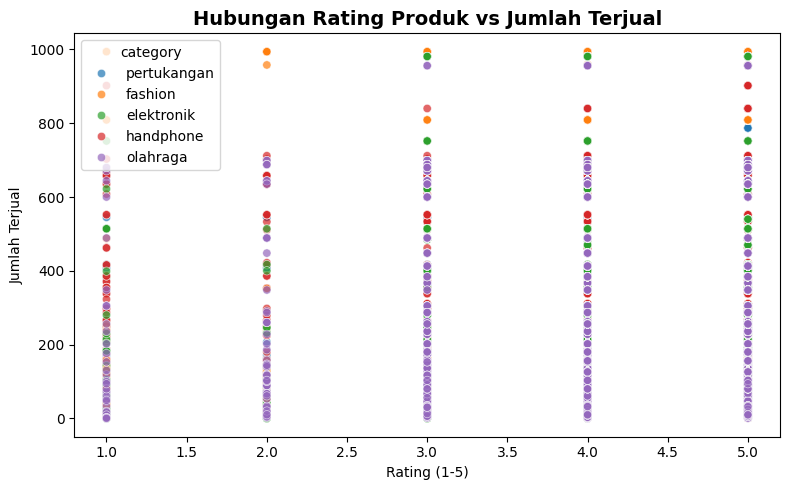

In [3]:
# 3. Korelasi Antara Rating vs Total Sold (Scatter Plot)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='rating', y='sold', hue='category', alpha=0.7)
plt.title('Hubungan Rating Produk vs Jumlah Terjual', fontsize=14, fontweight='bold')
plt.xlabel('Rating (1-5)')
plt.ylabel('Jumlah Terjual')
plt.tight_layout()
plt.savefig("../outputs/figures/rating_vs_sold.png", dpi=300)
plt.show()

In [8]:
# 4. Text Mining: Ekstraksi Kata Kunci pada Ulasan Rating Low (1-2) vs High (4-5)
# Pastikan kolom sentimen ada dan normalisasi nilai agar cocok saat filter
if 'sentiment_category' not in df.columns:
    if 'sentinent_category' in df.columns:
        df = df.rename(columns={'sentinent_category': 'sentiment_category'})
    else:
        raise KeyError("Kolom 'sentiment_category' tidak ditemukan di DataFrame.")

df['sentiment_category'] = df['sentiment_category'].astype(str).str.strip().str.title()

negative_reviews = df[df['sentiment_category'] == 'Negative']['text'].dropna()
print("--- Contoh Ulasan Negatif / Keluhan ---")
print(negative_reviews.head(10).to_list())

--- Contoh Ulasan Negatif / Keluhan ---
['Pesanan gx sesuai dgn yg d gambar', 'Pengiriman dan respon super cepat. Tpi barang tidak sesuai gambar dan tidak kuat untuk menembus jok motor.', 'barang yg dikirim tidak sesuai pesanan', 'Php, bilang isi ada diseskripsi pas dipesen berbeda, mubajir rp50.000 ternyata isinya ga cocok', 'barang jelek copot&#34; terus tmpat taro isinya', 'Beli staples gak jual isinya... hanya sekali pake.... ckckck', 'Sebaiknya kalau mau ngirim barang...diperiksa dulu gan, kondisi  barangnya layak apa gak gitu loh.\n(Isinya karatan semua)', 'Produk tidak sesuai, order prohex yg dikirim ini', 'brg sdh diterima.................', 'tidak bisa buat masang jok gak ke pake']


In [ ]:
# 5. Simpan Grafik ke 'outputs/figures/sentiment_distribution.png'
